In [76]:
from astropy.io import fits
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

# Plot formatting
cm = 0.3937008
mpl.rcParams["figure.dpi"] = 300
mpl.rcParams["figure.figsize"] = (8*cm, 5*cm)
mpl.rcParams["lines.linewidth"] = 0.5
mpl.rcParams["font.size"] = 5
mpl.rcParams["font.family"] = "serif"
mpl.rcParams["errorbar.capthick"] = 0.2
mpl.rcParams["errorbar.capsize"] = 1.5
mpl.rcParams["lines.markersize"] = 0.1

In [77]:
def FindBounds(data, sigma=1):

    mean = np.mean(data)
    std = np.std(data)

    expression = f"(RATE<={regions[0]})&&(RATE<={regions[1]})"

    return expression, mean, std

def PlotBounds(data, mean, std):

    fig, ax = plt.subplots()

    ax.set_xlabel("Time")
    ax.set_ylabel("Rate (counts s$^{-1}$)")

    ax.plot(data["TIME"], data["RATE"], c="k")
    ax.hlines(mean, min(data["TIME"]), max(data["TIME"]), color="r")
    ax.hlines([mean-std, mean+std], min(data["TIME"]), max(data["TIME"]), color="r", ls="--")

    cond = ((data["RATE"]<=mean+std) & (data["RATE"]>=mean-std))

    ax.plot(data["TIME"][cond], data["RATE"][cond], color="b")

    ax.set_xlim(min(data["TIME"]), max(data["TIME"]))

    return fig, ax

In [78]:
hdu = fits.open("../data/pn_ltcrv.fits")

(RATE<=22.777652195907933)&&(RATE<=11.78735527793362)


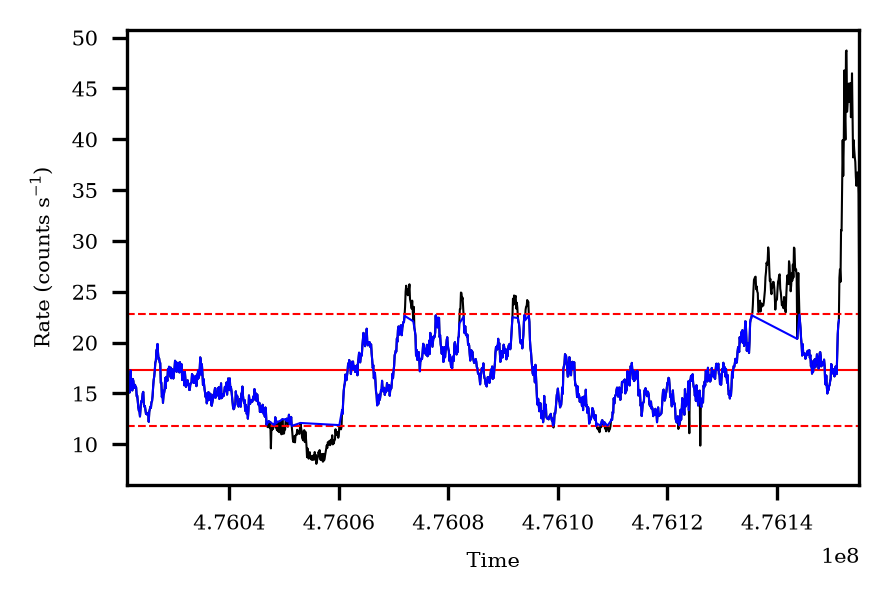

In [79]:
data = hdu[1].data

expression, mean, std = FindBounds(data["RATE"], 1)

PlotBounds(data, mean, std)

print(expression)